# PRISMA 2020 flow diagram (CNKI systematic review, 96 included studies)

Editable matplotlib version of the screening diagram. **Everything you may want to change is in the two "EDIT HERE" cells**: numbers and texts (cell 2) and positions/colours (cell 3). Then run all cells: the figure is saved as PNG (300 dpi), PDF and SVG next to this notebook.

**Updated to the final search (28 October 2026)** and to the PRISMA 2020 structure used in the manuscript (Section 3.4) and in the screening file `screening_v9_PRISMAequitycoding.xlsx` (sheet *PRISMA 2020*):
334 identified → 3 duplicates and 60 removed by the automated mitigation filter → 271 screened → 106 excluded → 165 sought → 34 not retrieved → 131 assessed → 35 excluded → **96 included (2010–2026)**.

**Fonts:** Chinese characters need a Chinese-capable font. The notebook looks for Microsoft YaHei / SimHei (Windows), PingFang SC (macOS) or Noto Sans CJK SC (Linux) and prints what it found.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib import font_manager

# Latin fonts first, then Chinese-capable fonts. Matplotlib falls back glyph by glyph,
# so Latin text uses the first font and Chinese characters use the first Chinese font.
LATIN_FONTS = ["Arial", "Helvetica", "DejaVu Sans"]
CHINESE_FONTS = ["Microsoft YaHei", "SimHei", "PingFang SC", "Noto Sans CJK SC", "Arial Unicode MS"]

installed = {f.name for f in font_manager.fontManager.ttflist}
use_fonts = [f for f in LATIN_FONTS + CHINESE_FONTS if f in installed]
plt.rcParams["font.family"] = use_fonts            # explicit list = glyph-by-glyph fallback
plt.rcParams["axes.unicode_minus"] = False

chinese_found = [f for f in CHINESE_FONTS if f in installed]
print("Fonts in use:", use_fonts)
if not chinese_found:
    print("WARNING: no Chinese-capable font found - Chinese characters will appear as empty boxes.")

Fonts in use: ['Arial', 'DejaVu Sans', 'Microsoft YaHei', 'SimHei']


In [ ]:
# ===================== EDIT HERE (1/2): numbers and texts =====================

# --- Numbers ---------------------------------------------------------------
N = dict(
    identified    = 334,  # records identified via CNKI professional search (academic journals)
    duplicates    = 3,    # removed before screening: duplicate records
    automation    = 60,   # removed before screening: automated mitigation filter (Table 3 terms, R script)
    screened      = 271,  # records screened on title, keywords and abstract
    excluded_ta   = 106,  # records excluded at title/abstract
    sought        = 165,  # reports sought for retrieval
    not_retrieved = 34,   # reports not retrieved (full text not available)
    assessed      = 131,  # reports assessed for eligibility (full text)
    excluded_ft   = 35,   # reports excluded after full-text assessment
    included      = 96,   # studies included in the review
)

# Exclusion reasons (title/abstract stage and full-text stage)
REASONS_TA = [("No substantive social/governance dimension", 37),
              ("Not a research article", 34),
              ("Mitigation focus", 18),
              ("Not adaptation-focused / off-topic", 15),
              ("Translation / not Chinese-authored", 2)]
REASONS_FT = [("Mitigation focus", 11),
              ("Not a research article", 10),
              ("Not adaptation-focused / off-topic", 6),
              ("No substantive social/governance dimension", 5),
              ("Translation / not Chinese-authored", 3)]

# Consistency checks: they stop the notebook if the flow does not add up
assert N["identified"] - N["duplicates"] - N["automation"] == N["screened"]
assert N["screened"] - N["excluded_ta"] == N["sought"]
assert N["sought"]   - N["not_retrieved"] == N["assessed"]
assert N["assessed"] - N["excluded_ft"] == N["included"]
assert sum(n for _, n in REASONS_TA) == N["excluded_ta"]
assert sum(n for _, n in REASONS_FT) == N["excluded_ft"]

# --- Texts -------------------------------------------------------------------
# Each box = list of (text, style). Styles: title, title2, bolditalic, italic, normal, item, n
MAIN = {
    "identified": [
        ("Records identified from CNKI (知网)", "title"),
        ("Professional search (专业检索), TKA field", "italic"),
        ("Academic journals (学术期刊) · search 28 Oct 2026", "italic"),
        (f"(n = {N['identified']})", "n"),
    ],
    "screened": [
        ("Records screened", "title"),
        ("Title · keywords · abstract", "italic"),
        (f"(n = {N['screened']})", "n"),
    ],
    "sought": [
        ("Reports sought for retrieval", "title"),
        (f"(n = {N['sought']})", "n"),
    ],
    "assessed": [
        ("Reports assessed for eligibility", "title"),
        ("Full-text reading (全文)", "italic"),
        (f"(n = {N['assessed']})", "n"),
    ],
    "included": [
        ("Studies included in review", "title"),
        ("纳入研究 · published 2010–2026", "italic"),
        ("Trend, co-occurrence, thematic and equity analysis", "italic"),
        (f"(n = {N['included']})", "n"),
    ],
}

SIDE = {
    "removed": [
        ("Records removed before screening:", "title2"),
        (f"Duplicate records (n = {N['duplicates']})", "item"),
        (f"Marked ineligible by automation tool (n = {N['automation']})", "item"),
        ("    mitigation exclusion terms, R script (Table 3)", "italic_left"),
    ],
    "excluded_ta": [("Records excluded:", "title")]
        + [(f"• {r} ({n})", "item") for r, n in REASONS_TA]
        + [(f"(n = {N['excluded_ta']})", "n")],
    "not_retrieved": [
        ("Reports not retrieved", "title"),
        ("Full text not available", "normal"),
        (f"(n = {N['not_retrieved']})", "n"),
    ],
    "excluded_ft": [("Reports excluded:", "title")]
        + [(f"• {r} ({n})", "item") for r, n in REASONS_FT]
        + [(f"(n = {N['excluded_ft']})", "n")],
}

HEADER = "Identification of studies via databases"
FOOTER = "PRISMA 2020 — Page MJ et al. BMJ 2021;372:n71. doi: 10.1136/bmj.n71"


In [ ]:
# ===================== EDIT HERE (2/2): positions, sizes, colours =====================
# Canvas in "pixels": 880 x 920 (figure = 8.8 x 9.2 inches at 100 dpi). y grows DOWNWARDS.
W, H = 880, 920

COL = dict(header_face="#E8A020", header_edge="#C98A1A", bar="#6395CB",
           box_face="white", box_edge="#2B2B2B", sub="#555555",
           arrow="#2B2B2B", arrow_last="#9A9A9A", sep="#CFCFCF", footer="#8A8A8A")

MX0, MX1 = 94, 405     # main column: left / right edge
SX0, SX1 = 445, 858    # side column: left / right edge

# box -> (x0, y0, x1, y1). Move or resize boxes here.
MAIN_POS = {
    "identified": (MX0,  95, MX1, 220),
    "screened":   (MX0, 290, MX1, 370),
    "sought":     (MX0, 446, MX1, 506),
    "assessed":   (MX0, 584, MX1, 664),
    "included":   (MX0, 744, MX1, 846),
}
SIDE_POS = {
    "removed":       (SX0,  95, SX1, 220),
    "excluded_ta":   (SX0, 250, SX1, 410),
    "not_retrieved": (SX0, 436, SX1, 516),
    "excluded_ft":   (SX0, 544, SX1, 704),
}

# horizontal arrows: main box -> side box
H_ARROWS = [("identified", "removed"), ("screened", "excluded_ta"),
            ("sought", "not_retrieved"), ("assessed", "excluded_ft")]

# blue phase bars on the left: (label, y_top, y_bottom)
PHASES = [("Identification", 95, 220), ("Screening", 250, 704), ("Included", 744, 846)]
BAR_X0, BAR_X1 = 27, 80

# dashed separators between phases (y positions) and their x-range
SEPARATORS = [235, 724]
SEP_X0, SEP_X1 = 27, 858

HEADER_BOX = (22, 10, 836, 50)   # x, y, width, height
FOOTER_Y = 892

# text styles (size in points; step = vertical distance to the next line in pixels)
STYLE = dict(
    title       = dict(size=11,  weight="bold",   style="normal", color="black", step=24),
    title2      = dict(size=11,  weight="bold",   style="normal", color="black", step=24),
    bolditalic  = dict(size=9.5, weight="bold",   style="italic", color="black", step=19),
    italic      = dict(size=8.5, weight="normal", style="italic", color=COL["sub"], step=16),
    italic_left = dict(size=8.5, weight="normal", style="italic", color=COL["sub"], step=16, ha="left"),
    normal      = dict(size=9.5, weight="normal", style="normal", color="black", step=17),
    item        = dict(size=9.5, weight="normal", style="normal", color="black", step=19, ha="left"),
    n           = dict(size=11,  weight="bold",   style="normal", color="black", step=0),
)
TOP_PAD   = 19    # distance from box top to the first text line
N_FROM_BOTTOM = 15  # distance of the (n = ...) line from the box bottom
BOX_LW = 1.4


In [ ]:
def draw_box(ax, pos, lines):
    x0, y0, x1, y1 = pos
    ax.add_patch(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0,
                                boxstyle="round,pad=0,rounding_size=7",
                                fc=COL["box_face"], ec=COL["box_edge"], lw=BOX_LW, zorder=2))
    cx, y = (x0 + x1) / 2, y0 + TOP_PAD
    for text, st in lines:
        s = STYLE[st]
        if st == "n":                                   # bottom-anchored count line
            ax.text(cx, y1 - N_FROM_BOTTOM, text, ha="center", va="center", fontsize=s["size"],
                    fontweight=s["weight"], zorder=3)
            continue
        ha = s.get("ha", "center")
        ax.text(x0 + 15 if ha == "left" else cx, y, text, ha=ha, va="center", fontsize=s["size"],
                fontweight=s["weight"], fontstyle=s["style"], color=s["color"], zorder=3)
        y += s["step"]


def arrow(ax, p_from, p_to, color):
    ax.annotate("", xy=p_to, xytext=p_from, zorder=1,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3,
                                shrinkA=0, shrinkB=0, mutation_scale=11))


def build_figure():
    fig = plt.figure(figsize=(W / 100, H / 100), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.axis("off")

    # header
    hx, hy, hw, hh = HEADER_BOX
    ax.add_patch(FancyBboxPatch((hx, hy), hw, hh, boxstyle="round,pad=0,rounding_size=7",
                                fc=COL["header_face"], ec=COL["header_edge"], lw=1.2, zorder=2))
    ax.text(hx + hw / 2, hy + hh / 2, HEADER, ha="center", va="center", fontsize=13, fontweight="bold", zorder=3)

    # phase bars and separators
    for label, ya, yb in PHASES:
        ax.add_patch(FancyBboxPatch((BAR_X0, ya), BAR_X1 - BAR_X0, yb - ya,
                                    boxstyle="round,pad=0,rounding_size=7", fc=COL["bar"], ec="none", zorder=2))
        ax.text((BAR_X0 + BAR_X1) / 2, (ya + yb) / 2, label, rotation=90, ha="center", va="center",
                color="white", fontsize=11, fontweight="bold", zorder=3)
    for y in SEPARATORS:
        ax.plot([SEP_X0, SEP_X1], [y, y], ls=(0, (4, 3)), color=COL["sep"], lw=1.2, zorder=1)

    # boxes
    for k, pos in MAIN_POS.items():
        draw_box(ax, pos, MAIN[k])
    for k, pos in SIDE_POS.items():
        draw_box(ax, pos, SIDE[k])

    # arrows: down the main column (the last one grey), and across to the side boxes
    keys = list(MAIN_POS)
    for i in range(len(keys) - 1):
        a, b = MAIN_POS[keys[i]], MAIN_POS[keys[i + 1]]
        xm = (a[0] + a[2]) / 2
        arrow(ax, (xm, a[3]), (xm, b[1]), COL["arrow_last"] if i == len(keys) - 2 else COL["arrow"])
    for m, s in H_ARROWS:
        a, b = MAIN_POS[m], SIDE_POS[s]
        arrow(ax, (a[2], (a[1] + a[3]) / 2), (b[0], (a[1] + a[3]) / 2), COL["arrow"])

    ax.text(W / 2, FOOTER_Y, FOOTER, ha="center", va="center", fontsize=8, color=COL["footer"])
    return fig

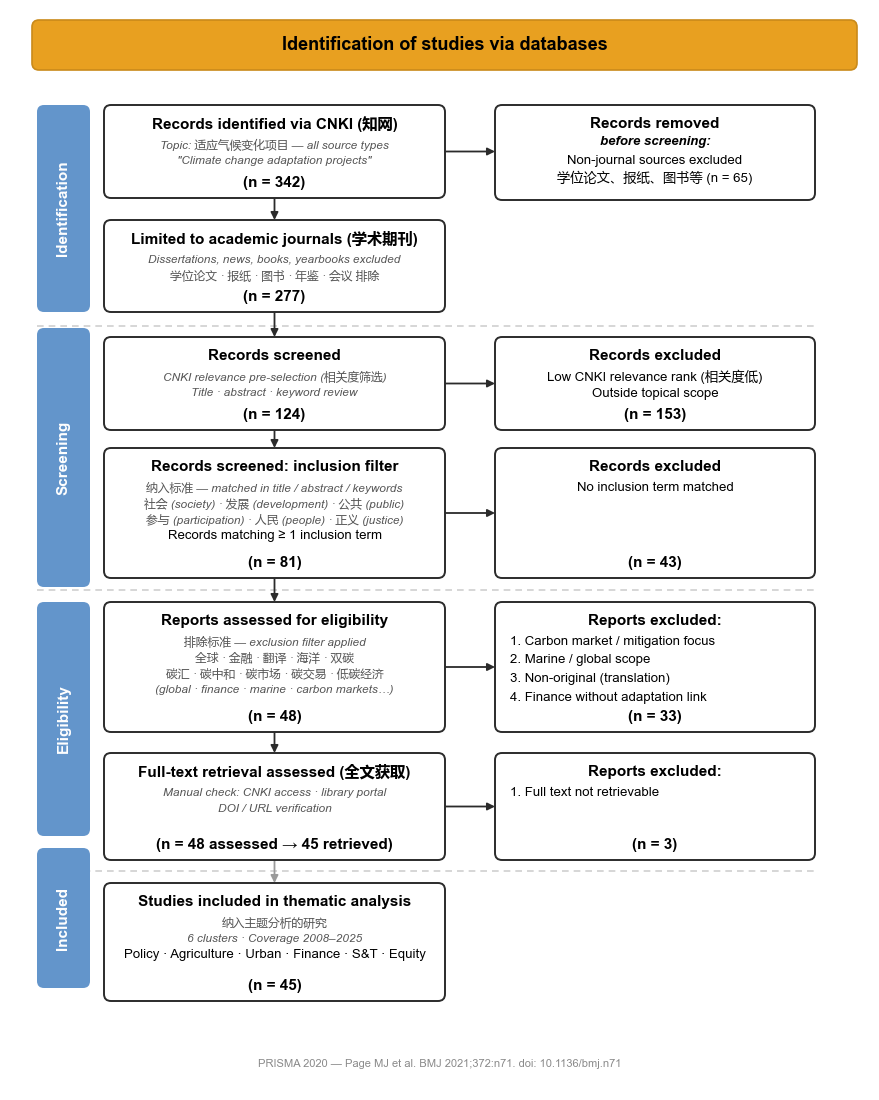

Saved: prisma_flow_diagram.png / .pdf / .svg


In [5]:
fig = build_figure()
fig.savefig("prisma_flow_diagram.png", dpi=300, facecolor="white")
fig.savefig("prisma_flow_diagram.pdf", facecolor="white")
fig.savefig("prisma_flow_diagram.svg", facecolor="white")
plt.show()
print("Saved: prisma_flow_diagram.png / .pdf / .svg")

## Quick tips for manual changes
- **Change a number**: edit it in the `N` dictionary (cell 2). The checks stop the notebook if the flow does not add up (e.g. 334 − 3 − 60 must be 271).
- **Change a text**: edit the strings in `MAIN` / `SIDE`. One tuple = one line. Styles: `title`, `bolditalic`, `italic`, `normal`, `item` (left-aligned list line), `n` (the count line at the bottom of the box).
- **Add or remove a line**: add or delete a tuple, then make the box taller or shorter in `MAIN_POS` / `SIDE_POS` (4th value = bottom edge, in pixels, y grows downwards).
- **Move things**: change the coordinates in `MAIN_POS`, `SIDE_POS`, `PHASES`, `SEPARATORS`.
- **Fonts and sizes**: `STYLE` (cell 3). If Chinese characters appear as empty boxes, install a Chinese font or add its name to `CHINESE_FONTS` (cell 2).